# Fase 5 - Actividad Final: Evaluacion Hold-out (Modelos Lineales)

Este notebook toma los **modelos finales ya entrenados** (SVM y Regresión Logística) y los evalúa contra el conjunto de datos `test_blind_set.csv`. Este conjunto de datos representa el 20% del corpus original y **jamás ha sido expuesto** a ningún proceso de entrenamiento.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time
import warnings

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

## 1. Carga del Conjunto de Prueba Ciego (Hold-out)

In [7]:
TEST_PATH = 'data/test_blind_set.csv'

df_test = pd.read_csv(TEST_PATH, sep=';')
df_test['texto_lineal'] = df_test['texto_lineal'].fillna('')

print(f"Conjunto Ciego (Hold-out) cargado.")
print(f"   Total de registros : {len(df_test):,}")
print(f"   Distribucion de clases:\n{df_test['label'].value_counts(normalize=True) * 100}")

y_true = df_test['label'].values

Conjunto Ciego (Hold-out) cargado.
   Total de registros : 11,447
   Distribucion de clases:
label
1    58.277278
0    41.722722
Name: proportion, dtype: float64


## 2. Helper: Funcion para graficar Matriz de Confusion

In [8]:
def graficar_matriz(y_real, y_pred, titulo, ax):
    cm = confusion_matrix(y_real, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Falso (0)', 'Real (1)'],
                yticklabels=['Falso (0)', 'Real (1)'])
    ax.set_title(titulo, fontsize=14)
    ax.set_ylabel('Valor Real')
    ax.set_xlabel('Prediccion')

## 3. Evaluacion: Modelos Lineales (SVM y Regresion Logistica)

In [9]:
RUTA_SVM = 'data/best_svm_ampliada.joblib'
RUTA_LOG = 'data/best_log_ampliada.joblib'

resultados_lineales = {}

# ---------------------------------------------------------
# SVM (LinearSVC)
# ---------------------------------------------------------
if os.path.exists(RUTA_SVM):
    print("Evaluando SVM (LinearSVC) con malla ampliada...")
    pipeline_svm = joblib.load(RUTA_SVM)
    
    t_start = time.perf_counter()
    y_pred_svm = pipeline_svm.predict(df_test[['texto_lineal']])
    t_end = time.perf_counter()
    
    f1_svm = f1_score(y_true, y_pred_svm, average='macro')
    acc_svm = accuracy_score(y_true, y_pred_svm)
    
    resultados_lineales['SVM'] = {
        'pred': y_pred_svm,
        'f1': f1_svm,
        'acc': acc_svm,
        'time_ms_per_sample': ((t_end - t_start) / len(df_test)) * 1000
    }
    print(f"  [OK] F1-Macro: {f1_svm:.4f} | Accuracy: {acc_svm:.4f}")
else:
    print(f"  [ERROR] No se encontro {RUTA_SVM}")

# ---------------------------------------------------------
# Regresion Logistica
# ---------------------------------------------------------
if os.path.exists(RUTA_LOG):
    print("\nEvaluando Regresion Logistica con malla ampliada...")
    pipeline_log = joblib.load(RUTA_LOG)
    
    t_start = time.perf_counter()
    y_pred_log = pipeline_log.predict(df_test[['texto_lineal']])
    t_end = time.perf_counter()
    
    f1_log = f1_score(y_true, y_pred_log, average='macro')
    acc_log = accuracy_score(y_true, y_pred_log)
    
    resultados_lineales['LogReg'] = {
        'pred': y_pred_log,
        'f1': f1_log,
        'acc': acc_log,
        'time_ms_per_sample': ((t_end - t_start) / len(df_test)) * 1000
    }
    print(f"  [OK] F1-Macro: {f1_log:.4f} | Accuracy: {acc_log:.4f}")
else:
    print(f"  [ERROR] No se encontro {RUTA_LOG}")

Evaluando SVM (LinearSVC) con malla ampliada...
  [OK] F1-Macro: 0.9067 | Accuracy: 0.9096

Evaluando Regresion Logistica con malla ampliada...
  [OK] F1-Macro: 0.9062 | Accuracy: 0.9090


## 4. Reporte Final

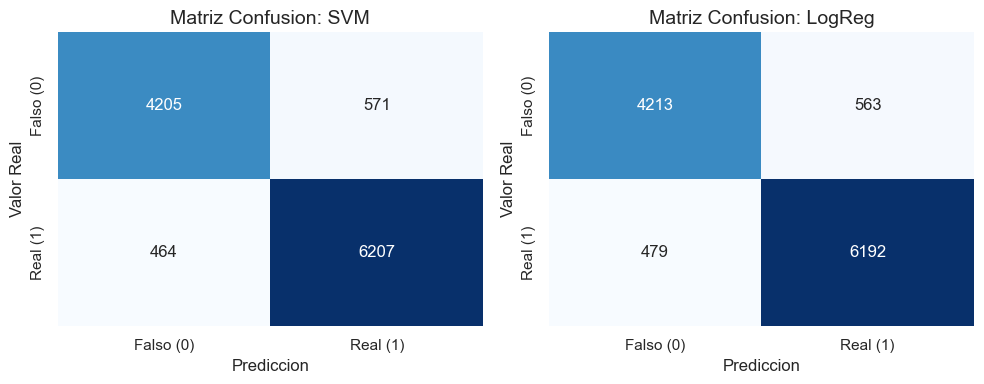

,F1-Score Macro,Accuracy,Tiempo / Noticia (ms)
Modelo,,,
SVM,0.9067,0.9096,0.04
LogReg,0.9062,0.9090,0.04



 REPORTE DE CLASIFICACION (HOLD-OUT) - SVM (LinearSVC)
              precision    recall  f1-score   support

       Falso       0.90      0.88      0.89      4776
        Real       0.92      0.93      0.92      6671

    accuracy                           0.91     11447
   macro avg       0.91      0.91      0.91     11447
weighted avg       0.91      0.91      0.91     11447


 REPORTE DE CLASIFICACION (HOLD-OUT) - REGRESION LOGISTICA
              precision    recall  f1-score   support

       Falso       0.90      0.88      0.89      4776
        Real       0.92      0.93      0.92      6671

    accuracy                           0.91     11447
   macro avg       0.91      0.91      0.91     11447
weighted avg       0.91      0.91      0.91     11447



In [10]:
num_modelos = len(resultados_lineales)

if num_modelos > 0:
    fig, axes = plt.subplots(1, num_modelos, figsize=(5 * num_modelos, 4))
    if num_modelos == 1:
        axes = [axes]
        
    idx = 0
    resumen_lista = []
    
    for nombre, res in resultados_lineales.items():
        graficar_matriz(y_true, res['pred'], f"Matriz Confusion: {nombre}", axes[idx])
        resumen_lista.append({
            'Modelo': nombre,
            'F1-Score Macro': round(res['f1'], 4),
            'Accuracy': round(res['acc'], 4),
            'Tiempo / Noticia (ms)': round(res['time_ms_per_sample'], 2)
        })
        idx += 1
        
    plt.tight_layout()
    plt.show()
    
    df_resumen = pd.DataFrame(resumen_lista)
    display(df_resumen.set_index('Modelo'))
    
    if 'SVM' in resultados_lineales:
        print("\n" + "="*60)
        print(" REPORTE DE CLASIFICACION (HOLD-OUT) - SVM (LinearSVC)")
        print("="*60)
        print(classification_report(y_true, resultados_lineales['SVM']['pred'], target_names=['Falso', 'Real']))
    
    if 'LogReg' in resultados_lineales:
        print("\n" + "="*60)
        print(" REPORTE DE CLASIFICACION (HOLD-OUT) - REGRESION LOGISTICA")
        print("="*60)
        print(classification_report(y_true, resultados_lineales['LogReg']['pred'], target_names=['Falso', 'Real']))
else:
    print("No se encontro ningun modelo para evaluar.")